# Model comparison: one validation workflow for every scenario model

All models in `scenario_lab.models.MODELS` are scored by the same code (`scenario_lab.validation`), with the same data, origins, seeds and path counts. A model only has to provide `fit(changes)` and `simulate(params, y0, n_paths, n_days, seed)` (see `models/__init__.py`); adding the neural SDE means registering it there and re-running this notebook.

**Workflow** (identical for every model, fit on data up to the forecast origin only):

- **Design A:** one cut at the end of 2018; coverage of realised 250-day changes inside the simulated 5-95% and 25-75% bands, on the test windows and on the training windows.
- **Design B:** expanding window with year-end origins; each origin is tested on the 250 windows starting in the following year. Per-origin coverage and the ratio of simulated to actual daily std.
- **Variance ratio:** `var(250-day change) / (250 * var(daily change))`, simulated against realised.

Headline numbers (`summary`, lower is better): mean |coverage - nominal| in design A (test) and B, and mean |log(simulated / actual daily std)| in design B. To run on another market set `CURVE` below (`"DE"` Bundesbank from 2000, `"US"` Federal Reserve from 1985) and the first origin year.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scenario_lab.data import load_curve
from scenario_lab import validation as v
from scenario_lab.models import MODELS
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

CURVE = "AAA"                                   # "AAA" (ECB, 2004-), "DE" (Bundesbank, 2000-), "US" (Fed GSW, 1985-)
FIRST_ORIGIN = {"AAA": 2012, "ALL": 2012, "DE": 2006, "US": 1992}[CURVE]
levels = load_curve(CURVE)
origins = v.year_end_origins(FIRST_ORIGIN, levels.index[-1].year - 2)
print(CURVE, levels.index[0].date(), "to", levels.index[-1].date(), "| origins", origins[0][:4], "-", origins[-1][:4], f"({len(origins)})")
print("models:", [m.name for m in MODELS.values()])

AAA 2004-09-06 to 2026-11-19 | origins 2012 - 2024 (13)
models: ['var1', 'var1_garch']


In [2]:
results = v.compare(MODELS, levels, origins, cut=v.FIT_END)      # fits every model at every origin: a few minutes

## Summary

One row per model, same data and settings. Lower is better in every column.

In [3]:
print(v.summary(results).round(3))

            A_dev90  B_dev90  B_dev50  B_logstd
var1          0.134    0.179    0.300     0.423
var1_garch    0.170    0.185    0.302     0.361


## Design A: single cut (end-2018)

Coverage on the test windows (start at or after the cut) and on the training windows, per maturity. Nominal 0.90 for the 5-95% band and 0.50 for 25-75%.

In [4]:
for key, nominal in [("cov90", 0.90), ("cov50", 0.50)]:
    tab = pd.concat({r["name"]: r["A"][key] for r in results.values()}, axis=1)
    print(f"coverage, nominal {nominal:.2f}  (test windows: {next(iter(results.values()))['A']['n_test_windows']})")
    print(tab.round(3), "\n")

coverage, nominal 0.90  (test windows: 1764)
      var1        var1_garch       
     train   test      train   test
1Y   0.734  0.563      0.711  0.520
2Y   0.809  0.708      0.756  0.632
5Y   0.873  0.789      0.798  0.756
10Y  0.912  0.811      0.829  0.794
20Y  0.942  0.840      0.878  0.823
30Y  0.967  0.885      0.938  0.852 

coverage, nominal 0.50  (test windows: 1764)
      var1        var1_garch       
     train   test      train   test
1Y   0.489  0.397      0.412  0.372
2Y   0.546  0.494      0.452  0.471
5Y   0.483  0.573      0.413  0.518
10Y  0.538  0.544      0.467  0.458
20Y  0.598  0.536      0.517  0.455
30Y  0.644  0.580      0.536  0.491 



## Design B: expanding window

Per-origin coverage of the 5-95% band (blue: band too wide, red: too narrow) for each model, then the ratio of simulated to actual daily std in the test year (1 = calibrated).

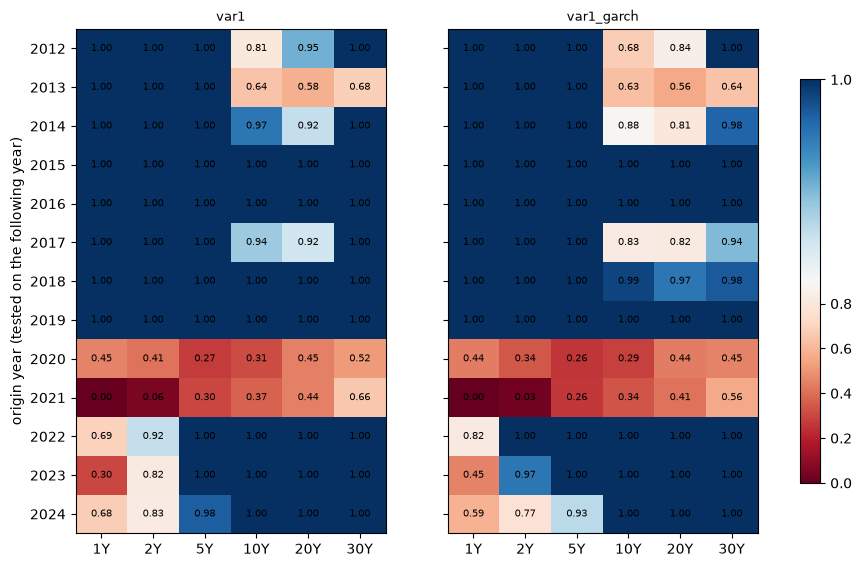

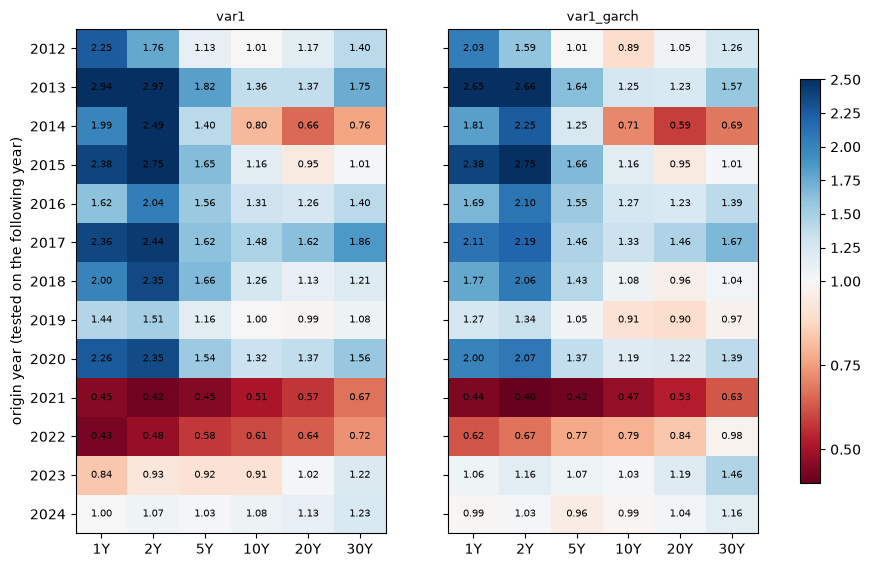

In [5]:
v.plot_heatmaps(results, "cov90", 0.9); plt.show()
v.plot_heatmaps(results, "std_ratio"); plt.show()

## Variance ratio

How fast the 250-day spread grows relative to the daily volatility. Realised values come from all overlapping windows; each model is fitted on the full sample and simulated from today's curve.

In [6]:
print(v.variance_ratio_table(MODELS, levels, n_paths=25_000, n_days=v.HORIZON, seed=0).round(2))

     realised  var1  var1_garch
1Y       5.68  1.14        1.18
2Y       2.45  1.11        1.14
5Y       1.39  1.04        1.06
10Y      1.20  1.04        1.06
20Y      1.07  1.09        1.12
30Y      0.88  1.10        1.13
